# A/B Testing: Publicidad estática (A) vs. Publicidad variante (B)

**Caso de estudio**

Una tienda online quiere decidir qué anuncio estático (banner) usar en su sitio web:

- **Anuncio A (base / control):** el anuncio actual, con el que ya se tiene histórico.
- **Anuncio B (variante / tratamiento):** un nuevo diseño propuesto.

Cada visitante ve aleatoriamente uno de los dos anuncios. Medimos si el visitante hace **clic** (y opcionalmente si **convierte**, es decir compra). El objetivo es responder: **¿el Anuncio B tiene una tasa de clics/conversión significativamente distinta a la del Anuncio A?**

Este notebook:
1. Simula datos realistas de un experimento A/B (impresiones, clics, conversiones).
2. Calcula métricas descriptivas (CTR, tasa de conversión) por grupo.
3. Visualiza los resultados: intervalos de confianza, embudo de conversión y comparativa combinada.
4. Aplica pruebas de hipótesis (z-test de proporciones y chi-cuadrado) para determinar significancia estadística.
5. Muestra la evolución del experimento día a día.
6. Da una conclusión y recomendación de negocio.

> Nota: los datos son **simulados**. Para usar datos reales, sustituye la celda de simulación por la carga de tu propio CSV (impresiones, clics, conversiones por visitante o agregados por grupo).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.stats.proportion import proportions_ztest, proportion_confint

np.random.seed(42)
plt.rcParams['figure.figsize'] = (8, 5)

## 1. Simulación del experimento

Simulamos visitantes que ven el Anuncio A (base) o el Anuncio B (variante). Cada visitante:
- Hace **clic** en el anuncio o no (evento binario, modelado con una tasa de clics real "desconocida" `p_click`).
- Si hace clic, puede **convertir** (comprar) o no (tasa de conversión condicional al clic, `p_convert_given_click`).

Supondremos que el Anuncio B tiene una mejora real pequeña en CTR (esto es lo que la prueba estadística debe detectar o no, según el tamaño de muestra).

In [2]:
# Parámetros "reales" de la simulación (desconocidos en un experimento real)
n_a = 15000          # impresiones del Anuncio A (base)
n_b = 15000          # impresiones del Anuncio B (variante)

p_click_a = 0.08            # CTR real del Anuncio A
p_click_b = 0.095           # CTR real del Anuncio B (ligera mejora)

p_convert_given_click_a = 0.10   # tasa de conversión condicional al clic, Anuncio A
p_convert_given_click_b = 0.15   # tasa de conversión condicional al clic, Anuncio B (mejora grande)

# Simular clics (1 = clic, 0 = no clic) por visitante
clicks_a = np.random.binomial(1, p_click_a, n_a)
clicks_b = np.random.binomial(1, p_click_b, n_b)

# Simular conversiones solo entre quienes hicieron clic
conversions_a = np.where(clicks_a == 1, np.random.binomial(1, p_convert_given_click_a, n_a), 0)
conversions_b = np.where(clicks_b == 1, np.random.binomial(1, p_convert_given_click_b, n_b), 0)

df = pd.DataFrame({
    'grupo': ['A'] * n_a + ['B'] * n_b,
    'anuncio': ['Anuncio A (base)'] * n_a + ['Anuncio B (variante)'] * n_b,
    'click': np.concatenate([clicks_a, clicks_b]),
    'conversion': np.concatenate([conversions_a, conversions_b]),
})

df.head()

,grupo,anuncio,click,conversion
0,A,Anuncio A (base),0,0
1,A,Anuncio A (base),1,0
2,A,Anuncio A (base),0,0
3,A,Anuncio A (base),0,0
4,A,Anuncio A (base),0,0


## 2. Métricas descriptivas por grupo

In [3]:
resumen = df.groupby('anuncio').agg(
    impresiones=('click', 'size'),
    clics=('click', 'sum'),
    conversiones=('conversion', 'sum'),
)
resumen['ctr'] = resumen['clics'] / resumen['impresiones']
resumen['tasa_conversion'] = resumen['conversiones'] / resumen['impresiones']
resumen['conversion_por_clic'] = resumen['conversiones'] / resumen['clics']

resumen

,impresiones,clics,conversiones,ctr,tasa_conversion,conversion_por_clic
anuncio,,,,,,
Anuncio A (base),15000,1205,118,0.080333,0.007867,0.097925
Anuncio B (variante),15000,1405,204,0.093667,0.013600,0.145196


## 3. Visualización con intervalos de confianza (95%)

Comparamos el CTR y la tasa de conversión de cada anuncio, con su intervalo de confianza del 95% (método de Wilson), para ver qué tan solapados están los resultados.

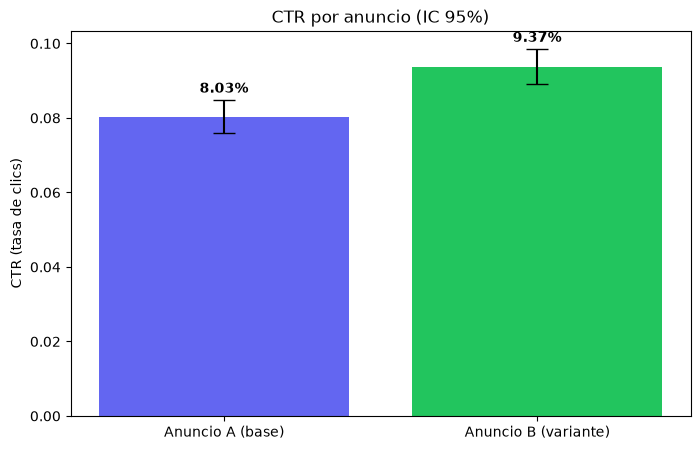

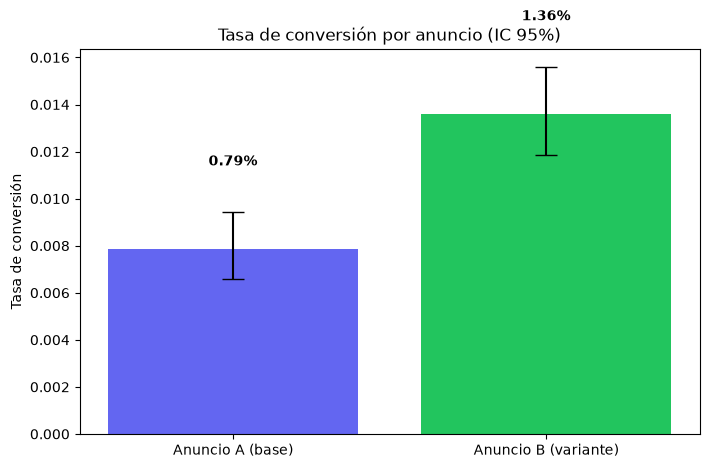

In [4]:
def plot_metric_with_ci(df, metric_col, title, ylabel):
    grupos = ['Anuncio A (base)', 'Anuncio B (variante)']
    tasas = []
    errores_inf = []
    errores_sup = []

    for g in grupos:
        sub = df[df['anuncio'] == g]
        exitos = sub[metric_col].sum()
        n = len(sub)
        tasa = exitos / n
        ci_low, ci_high = proportion_confint(exitos, n, alpha=0.05, method='wilson')
        tasas.append(tasa)
        errores_inf.append(tasa - ci_low)
        errores_sup.append(ci_high - tasa)

    fig, ax = plt.subplots()
    colores = ['#6366f1', '#22c55e']
    ax.bar(grupos, tasas, yerr=[errores_inf, errores_sup], capsize=8, color=colores)
    ax.set_title(title)
    ax.set_ylabel(ylabel)
    for i, t in enumerate(tasas):
        ax.text(i, t + errores_sup[i] + 0.002, f"{t:.2%}", ha='center', fontweight='bold')
    plt.show()

plot_metric_with_ci(df, 'click', 'CTR por anuncio (IC 95%)', 'CTR (tasa de clics)')
plot_metric_with_ci(df, 'conversion', 'Tasa de conversión por anuncio (IC 95%)', 'Tasa de conversión')

### 3.1 Embudo de conversión (impresiones → clics → ventas)

Visualizamos cuántos visitantes llegan a cada etapa del embudo en cada grupo. Ayuda a ver en qué paso se pierde más gente y dónde impacta realmente la variante B.

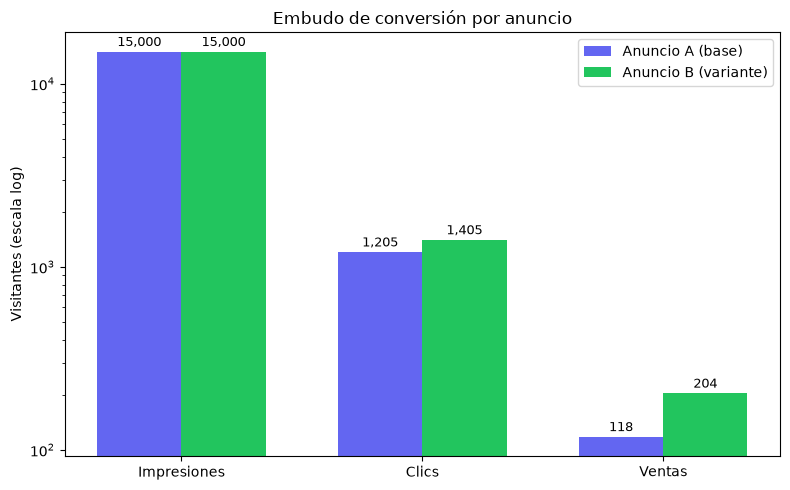

In [5]:
etapas = ['Impresiones', 'Clics', 'Ventas']
valores_a = [resumen.loc['Anuncio A (base)', 'impresiones'],
             resumen.loc['Anuncio A (base)', 'clics'],
             resumen.loc['Anuncio A (base)', 'conversiones']]
valores_b = [resumen.loc['Anuncio B (variante)', 'impresiones'],
             resumen.loc['Anuncio B (variante)', 'clics'],
             resumen.loc['Anuncio B (variante)', 'conversiones']]

x = np.arange(len(etapas))
ancho = 0.35

fig, ax = plt.subplots()
barras_a = ax.bar(x - ancho/2, valores_a, ancho, label='Anuncio A (base)', color='#6366f1')
barras_b = ax.bar(x + ancho/2, valores_b, ancho, label='Anuncio B (variante)', color='#22c55e')

ax.set_yscale('log')
ax.set_xticks(x)
ax.set_xticklabels(etapas)
ax.set_ylabel('Visitantes (escala log)')
ax.set_title('Embudo de conversión por anuncio')
ax.legend()

for barras in (barras_a, barras_b):
    for b in barras:
        altura = b.get_height()
        ax.annotate(f'{int(altura):,}', (b.get_x() + b.get_width() / 2, altura),
                    textcoords="offset points", xytext=(0, 4), ha='center', fontsize=9)

plt.tight_layout()
plt.show()

## 6. Conclusión y recomendación

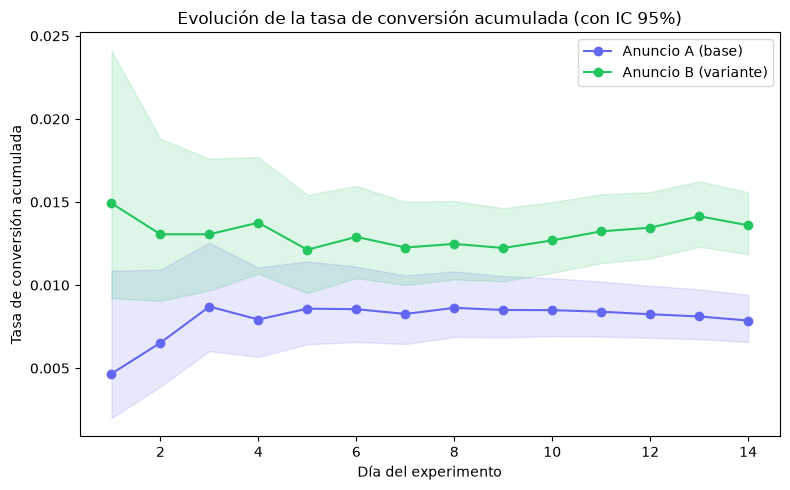

In [6]:
n_dias = 14
df_a = df[df['anuncio'] == 'Anuncio A (base)'].reset_index(drop=True)
df_b = df[df['anuncio'] == 'Anuncio B (variante)'].reset_index(drop=True)
df_a = df_a.assign(dia=(np.arange(len(df_a)) % n_dias) + 1)
df_b = df_b.assign(dia=(np.arange(len(df_b)) % n_dias) + 1)

def serie_acumulada(df_grupo, metric_col):
    por_dia = df_grupo.groupby('dia')[metric_col].agg(['sum', 'count']).sort_index()
    acumulado_exitos = por_dia['sum'].cumsum()
    acumulado_n = por_dia['count'].cumsum()
    tasa = acumulado_exitos / acumulado_n
    ci_low, ci_high = proportion_confint(acumulado_exitos, acumulado_n, alpha=0.05, method='wilson')
    return por_dia.index, tasa, ci_low, ci_high

dias_a, tasa_a_t, ci_low_a, ci_high_a = serie_acumulada(df_a, 'conversion')
dias_b, tasa_b_t, ci_low_b, ci_high_b = serie_acumulada(df_b, 'conversion')

fig, ax = plt.subplots()
ax.plot(dias_a, tasa_a_t, label='Anuncio A (base)', color='#6366f1', marker='o')
ax.fill_between(dias_a, ci_low_a, ci_high_a, color='#6366f1', alpha=0.15)
ax.plot(dias_b, tasa_b_t, label='Anuncio B (variante)', color='#22c55e', marker='o')
ax.fill_between(dias_b, ci_low_b, ci_high_b, color='#22c55e', alpha=0.15)

ax.set_xlabel('Día del experimento')
ax.set_ylabel('Tasa de conversión acumulada')
ax.set_title('Evolución de la tasa de conversión acumulada (con IC 95%)')
ax.legend()
plt.tight_layout()
plt.show()

## 7. Usar tus propios datos

Para reemplazar la simulación por datos reales, carga un CSV con una fila por visitante (o por grupo agregado) con columnas `grupo` (`A`/`B`), `click` (0/1) y `conversion` (0/1), por ejemplo:

```python
df = pd.read_csv('mi_experimento.csv')
```

y vuelve a ejecutar las celdas desde la sección 2 en adelante.

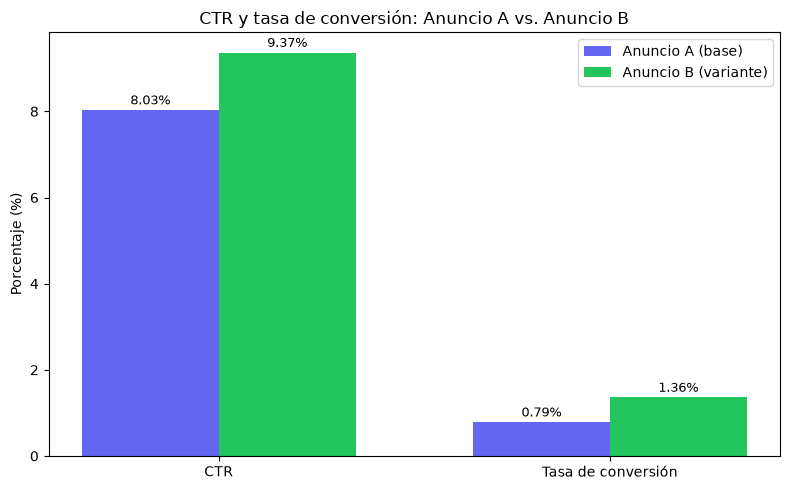

In [7]:
metricas = ['CTR', 'Tasa de conversión']
valores_a_pct = [resumen.loc['Anuncio A (base)', 'ctr'] * 100,
                 resumen.loc['Anuncio A (base)', 'tasa_conversion'] * 100]
valores_b_pct = [resumen.loc['Anuncio B (variante)', 'ctr'] * 100,
                 resumen.loc['Anuncio B (variante)', 'tasa_conversion'] * 100]

x = np.arange(len(metricas))
ancho = 0.35

fig, ax = plt.subplots()
barras_a = ax.bar(x - ancho/2, valores_a_pct, ancho, label='Anuncio A (base)', color='#6366f1')
barras_b = ax.bar(x + ancho/2, valores_b_pct, ancho, label='Anuncio B (variante)', color='#22c55e')

ax.set_xticks(x)
ax.set_xticklabels(metricas)
ax.set_ylabel('Porcentaje (%)')
ax.set_title('CTR y tasa de conversión: Anuncio A vs. Anuncio B')
ax.legend()

for barras in (barras_a, barras_b):
    for b in barras:
        altura = b.get_height()
        ax.annotate(f'{altura:.2f}%', (b.get_x() + b.get_width() / 2, altura),
                    textcoords="offset points", xytext=(0, 4), ha='center', fontsize=9)

plt.tight_layout()
plt.show()

## 4. Prueba de hipótesis

**Hipótesis nula (H0):** no hay diferencia real en la tasa de clics (o conversión) entre el Anuncio A y el Anuncio B.

**Hipótesis alternativa (H1):** las tasas son diferentes.

Usamos:
- **Z-test de proporciones** (`proportions_ztest`) para comparar directamente las dos proporciones.
- **Chi-cuadrado de independencia** como verificación alternativa sobre la tabla de contingencia.

Nivel de significancia: `alpha = 0.05`.

In [8]:
alpha = 0.05

def evaluar_metrica(df, metric_col, nombre_metrica):
    exitos = df.groupby('anuncio')[metric_col].sum()
    n = df.groupby('anuncio')[metric_col].count()

    exitos_vec = np.array([exitos['Anuncio A (base)'], exitos['Anuncio B (variante)']])
    n_vec = np.array([n['Anuncio A (base)'], n['Anuncio B (variante)']])

    z_stat, p_value = proportions_ztest(exitos_vec, n_vec, alternative='two-sided')

    tabla = pd.crosstab(df['anuncio'], df[metric_col])
    chi2, p_chi2, dof, expected = stats.chi2_contingency(tabla)

    print(f"--- {nombre_metrica} ---")
    print(f"Tasa A: {exitos_vec[0] / n_vec[0]:.4f}  |  Tasa B: {exitos_vec[1] / n_vec[1]:.4f}")
    print(f"Z-test de proporciones -> z = {z_stat:.3f}, p-valor = {p_value:.4f}")
    print(f"Chi-cuadrado           -> chi2 = {chi2:.3f}, p-valor = {p_chi2:.4f}")

    if p_value < alpha:
        print(f"Resultado: diferencia ESTADÍSTICAMENTE SIGNIFICATIVA (p < {alpha}).")
    else:
        print(f"Resultado: NO hay evidencia suficiente de diferencia (p >= {alpha}).")
    print()

    return p_value

p_click = evaluar_metrica(df, 'click', 'CTR (clics / impresiones)')
p_conv = evaluar_metrica(df, 'conversion', 'Tasa de conversión (conversiones / impresiones)')

--- CTR (clics / impresiones) ---
Tasa A: 0.0803  |  Tasa B: 0.0937
Z-test de proporciones -> z = -4.097, p-valor = 0.0000
Chi-cuadrado           -> chi2 = 16.619, p-valor = 0.0000
Resultado: diferencia ESTADÍSTICAMENTE SIGNIFICATIVA (p < 0.05).

--- Tasa de conversión (conversiones / impresiones) ---
Tasa A: 0.0079  |  Tasa B: 0.0136
Z-test de proporciones -> z = -4.819, p-valor = 0.0000
Chi-cuadrado           -> chi2 = 22.681, p-valor = 0.0000
Resultado: diferencia ESTADÍSTICAMENTE SIGNIFICATIVA (p < 0.05).



## 5. Conclusión y recomendación

In [9]:
ctr_a = resumen.loc['Anuncio A (base)', 'ctr']
ctr_b = resumen.loc['Anuncio B (variante)', 'ctr']
mejora_relativa_ctr = (ctr_b - ctr_a) / ctr_a * 100

conv_a = resumen.loc['Anuncio A (base)', 'tasa_conversion']
conv_b = resumen.loc['Anuncio B (variante)', 'tasa_conversion']
mejora_relativa_conv = (conv_b - conv_a) / conv_a * 100

print(f"CTR Anuncio A (base):     {ctr_a:.2%}")
print(f"CTR Anuncio B (variante): {ctr_b:.2%}")
print(f"Mejora relativa de B sobre A en CTR: {mejora_relativa_ctr:+.1f}%")
print()
print(f"Tasa de conversión Anuncio A (base):     {conv_a:.2%}")
print(f"Tasa de conversión Anuncio B (variante): {conv_b:.2%}")
print(f"Mejora relativa de B sobre A en conversión (ventas): {mejora_relativa_conv:+.1f}%")
print()

if p_click < alpha and ctr_b > ctr_a:
    print("Clics: Adoptar el Anuncio B. La mejora en CTR es estadísticamente "
          "significativa y positiva frente al Anuncio A (base).")
elif p_click < alpha and ctr_b < ctr_a:
    print("Clics: Mantener el Anuncio A (base). El Anuncio B tiene un CTR "
          "significativamente más bajo.")
else:
    print("Clics: No hay evidencia suficiente de diferencia en CTR entre A y B.")

if p_conv < alpha and conv_b > conv_a:
    print("Ventas: El Anuncio B también genera significativamente MÁS CONVERSIONES "
          "(ventas) que el Anuncio A. Recomendación final: adoptar el Anuncio B.")
elif p_conv < alpha and conv_b < conv_a:
    print("Ventas: El Anuncio B genera significativamente MENOS conversiones que el "
          "Anuncio A, pese a tener mejor CTR. Recomendación final: evaluar con cuidado "
          "antes de cambiar, priorizando ventas sobre clics.")
else:
    print("Ventas: No hay evidencia suficiente de diferencia en conversiones entre A y B. "
          "Se sugiere aumentar el tamaño de muestra o la duración del experimento.")

CTR Anuncio A (base):     8.03%
CTR Anuncio B (variante): 9.37%
Mejora relativa de B sobre A en CTR: +16.6%

Tasa de conversión Anuncio A (base):     0.79%
Tasa de conversión Anuncio B (variante): 1.36%
Mejora relativa de B sobre A en conversión (ventas): +72.9%

Clics: Adoptar el Anuncio B. La mejora en CTR es estadísticamente significativa y positiva frente al Anuncio A (base).
Ventas: El Anuncio B también genera significativamente MÁS CONVERSIONES (ventas) que el Anuncio A. Recomendación final: adoptar el Anuncio B.


## 6. Usar tus propios datos

Para reemplazar la simulación por datos reales, carga un CSV con una fila por visitante (o por grupo agregado) con columnas `grupo` (`A`/`B`), `click` (0/1) y `conversion` (0/1), por ejemplo:

```python
df = pd.read_csv('mi_experimento.csv')
```

y vuelve a ejecutar las celdas desde la sección 2 en adelante.